
# Avocado Prices adathalmaz elemzése

**A kutatás során ezekre a kérdésekre keressük a válaszokat.**

1. **Mennyire jelezhető előre az avokádó ára trend, szezonalitás és régiós eltérések alapján, és mely időszakokban romlik el látványosan az előrejelzés?** *(Három egyszerű módszerrel becsüljük meg a hagyományos avokádó következő heti árát.)*


2. **Mekkora a bioavokádó felára, és mennyire állandó a régiók és az évek között?** *(Ugyanazon a héten és ugyanabban a régióban hasonlítjuk össze a két árat. A különbséget dollárban és százalékban is megadjuk.)*


3. **Mennyire mozog együtt a hagyományos és a bioavokádó ára?** *(Megnézzük, hasonló időszakokban drága-e a két típus, és azt is, hogy egyik hétről a másikra általában azonos irányba változik-e az áruk.)*


## Adatok értelmezése és előkészítése:

**Forrás:** Justin Kiggins *Avocado Prices* adathalmazát használom, amely a **Hass Avocado Board** amerikai bolti eladási adatain alapul. Egy sorban egy piac, heti avokádi eladási adati vannak (usd/db ár, bio e ?, méret, milyen kiszerelésben) Az adatok 2015 januárjától 2018 márciusái tartanak.

Egy sor egy adott hét, terület és avokádótípus adatait tartalmazza. A `region` oszlopban városi piacok, nagyobb régiók és a `TotalUS` országos összesítés is szerepel.

### Adathalmaz változói:

| Változó | Magyarázat | Példa (első sor értékei) |
|---|---|---:|
| `Date` | A megfigyelési hét, ez mindig vasárnap. | `2015-12-27` |
| `region` | A piac vagy területi neve (állam is lehet, több várost egybefogó piac, vagy régiós összesítés). | `Albany` |
| `type` | Típus. `conventional` = hagyományos, `organic` = bio. | `conventional` |
| `year` | Külön eltárolva év. | `2015` |
| `AveragePrice` | Avokádó átlagos eladási ára, (usd/db). | 1,33 |
| `Total Volume` | Adott piacon, a teljes eladott mennyiség (minden méretből és zacskóból). | 64 236,62 |
| `4046` | Kis méretű, darabonként értékesített mennyiség. | 1 036,74 |
| `4225` | Nagy méretű, darabonként értékesített mennyiség. | 54 454,85 |
| `4770` | Extra nagy méretű, darabonként értékesített mennyiség. | 48,16 |
| `Total Bags` | Zacskós kiszerelésben értékesített összes mennyiség. | 8 696,87 |
| `Small Bags` | Kis zacskós kiszerelésben mennyiség. | 8 603,62 |
| `Large Bags` | Nagy zacskós kiszerelésben mennyiség. | 93,25 |
| `XLarge Bags` | Extra nagy zacskós kiszerelésben mennyiség. | 0 |
| `Unnamed: 0` | A CSV-be mentett régi sorindex, az értékei ismétlődnek, az elemzésből elhagyható. | 0 |

Először ellenőrizzük, hogy minden héthez van-e adat, és előfordul-e, hogy ugyanaz a hét, régió és típus kétszer szerepel. Átnézzük az árak tartományát is. A CSV-ben lévő `Unnamed: 0` csak sorszám, ezért eltávolítjuk.

In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib import dates as mdates
from sklearn.linear_model import LinearRegression

DATA_PATH = Path("data/avocado.csv")
raw = pd.read_csv(DATA_PATH, parse_dates=["Date"])
data = raw.drop(columns=["Unnamed: 0"], errors="ignore")
data = data.sort_values(["region", "type", "Date"]).reset_index(drop=True)

plt.rcParams.update({
    "figure.dpi": 115,
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.axisbelow": True,
    "grid.alpha": 0.25,
    "legend.frameon": False,
})
BLUE, ORANGE, TEAL, GRAY = "#22558a", "#b34a21", "#13766d", "#5b6574"
MONTH_NAMES = ["Jan.", "Febr.", "Márc.", "Ápr.", "Máj.", "Jún.",
               "Júl.", "Aug.", "Szept.", "Okt.", "Nov.", "Dec."]

print(f"Adatforrás: {DATA_PATH} | eredeti méret: {raw.shape[0]:,} sor, {raw.shape[1]} oszlop")
print(f"Időszak: {data['Date'].min():%Y-%m-%d} – {data['Date'].max():%Y-%m-%d}")
print(f"Területi címkék: {data['region'].nunique()} | különböző hetek: {data['Date'].nunique()}")
display(data.head(10))
display(data[["AveragePrice"]].describe().round(2))

Adatforrás: data/avocado.csv | eredeti méret: 18,249 sor, 14 oszlop
Időszak: 2015-01-04 – 2018-03-25
Területi címkék: 54 | különböző hetek: 169


,Date,AveragePrice,Total Volume,4046,4225,4770,Total Bags,Small Bags,Large Bags,XLarge Bags,type,year,region
0,2015-01-04,1.22,40873.28,2819.50,28287.42,49.90,9716.46,9186.93,529.53,0.0,conventional,2015,Albany
1,2015-01-11,1.24,41195.08,1002.85,31640.34,127.12,8424.77,8036.04,388.73,0.0,conventional,2015,Albany
2,2015-01-18,1.17,44511.28,914.14,31540.32,135.77,11921.05,11651.09,269.96,0.0,conventional,2015,Albany
3,2015-01-25,1.06,45147.50,941.38,33196.16,164.14,10845.82,10103.35,742.47,0.0,conventional,2015,Albany
4,2015-02-01,0.99,70873.60,1353.90,60017.20,179.32,9323.18,9170.82,152.36,0.0,conventional,2015,Albany
5,2015-02-08,0.99,51253.97,1357.37,39111.81,163.25,10621.54,10113.10,508.44,0.0,conventional,2015,Albany
6,2015-02-15,1.06,41567.62,986.66,30045.51,222.42,10313.03,9979.87,333.16,0.0,conventional,2015,Albany
7,2015-02-22,1.07,45675.05,1088.38,35056.13,151.00,9379.54,9000.16,379.38,0.0,conventional,2015,Albany
8,2015-03-01,0.99,55595.74,629.46,45633.34,181.49,9151.45,8986.06,165.39,0.0,conventional,2015,Albany
9,2015-03-08,1.07,40507.36,795.68,30370.64,159.05,9181.99,8827.55,354.44,0.0,conventional,2015,Albany


,AveragePrice
count,18249.00
mean,1.41
std,0.40
min,0.44
25%,1.10
50%,1.37
75%,1.66
max,3.25


In [4]:
KEY = ["Date", "region", "type"]
calendar_weeks = pd.date_range(data["Date"].min(), data["Date"].max(), freq="W-SUN")
expected = pd.MultiIndex.from_product(
    [calendar_weeks, sorted(data["region"].unique()), sorted(data["type"].unique())],
    names=KEY,
)
observed = pd.MultiIndex.from_frame(data[KEY])
missing_rows = expected.difference(observed)

checks = pd.Series({
    "Hiányzó cellák": data.isna().sum().sum(),
    "Ismétlődő hét–régió–típus kulcsok": data.duplicated(KEY).sum(),
    "Hiányzó hét–régió–típus kombinációk": len(missing_rows),
    "Vasárnaptól eltérő dátumok": data["Date"].dt.dayofweek.ne(6).sum(),
    "Eltérések a dátum és az év között": data["Date"].dt.year.ne(data["year"]).sum(),
    "Nulla vagy negatív árak": data["AveragePrice"].le(0).sum(),
}, name="Darab")
display(checks.to_frame())
display(missing_rows.to_frame(index=False))
display(data.groupby(["year", "type"])["Date"].nunique().unstack().rename_axis(index="Év"))

SELECTED_REGIONS = [
    "California", "GreatLakes", "Midsouth", "Northeast",
    "Plains", "SouthCentral", "Southeast", "West",
]
regional = data.loc[data["region"].isin(SELECTED_REGIONS)].copy()
selected_index = pd.MultiIndex.from_product(
    [calendar_weeks, SELECTED_REGIONS, ["conventional", "organic"]], names=KEY
)
assert data.duplicated(KEY).sum() == 0
assert len(regional) == len(selected_index)
assert selected_index.difference(observed).empty
assert regional["AveragePrice"].gt(0).all()
print(f"A nyolc kiválasztott régió teljes mintája: {len(regional):,} sor.")

,Darab
Hiányzó cellák,0
Ismétlődő hét–régió–típus kulcsok,0
Hiányzó hét–régió–típus kombinációk,3
Vasárnaptól eltérő dátumok,0
Eltérések a dátum és az év között,0
Nulla vagy negatív árak,0


,Date,region,type
0,2015-12-06,WestTexNewMexico,organic
1,2017-06-18,WestTexNewMexico,organic
2,2017-06-25,WestTexNewMexico,organic


type,conventional,organic
Év,,
2015,52,52
2016,52,52
2017,53,53
2018,12,12


A nyolc kiválasztott régió teljes mintája: 2,704 sor.


A fájl meglévő soraiban nincsenek üres cellák, és minden hét/régió/típus kombináció egyszer szerepel. Három héten, a `WestTexNewMexico` bio avokádójáról teljesen hiányzik a sor.

A három vizsgálathoz nyolc nagyobb régiót választunk. Ezekben mindkét típus ára mind a 169 hétre megvan, így azonos időszakokat tudunk vizsgálni. A régiók egyforma súlyt kapnak az átlagokban. Az országos árat közvetlenül a fájl `TotalUS` soraiból olvassuk ki.

A számítások alapja a heti ár. Néhány ábrán hónapok szerint foglaljuk össze a heteket, hogy könnyebb legyen felismerni a mintákat. Egy hét ahhoz a hónaphoz tartozik, amelyikbe a vasárnapja esik. A 2018-as adatok márciusig tartanak. A teljes éveket összehasonlító ábrák ezért 2015-től 2017-ig tartanak.


## 1. Kérdés: Mennyire jelezhető előre a következő heti ár?

**Három dolgot keresünk az ábrákon:**
* **Trend:** *(merre tart az ár hosszabb idő alatt)*
* **Szezonalitás:** *(az év hasonló részében újra megjelenik egy minta)*
* **Régiós eltérés:** *(egy területen általában drágább, mint egy másikon)*

**Ábrák felépítése:**
Az első ábrán a **szürke vonal** a heti országos ár, a **kék vonal** az adott és a megelőző 12 hét átlaga, amely kisimítja a rövid ingadozásokat. Az alsó ábrán a teljes évek havi átlagait tessük egymás mellé. A régiós árszinteket 2015 és 2016 adataiból számoljuk, mert a modellek is ezt a két évet kapják meg a tanuláshoz.

> **Megjegyzés:** Most csak a **hagyományos avokádó** árakkal dolgozunk.


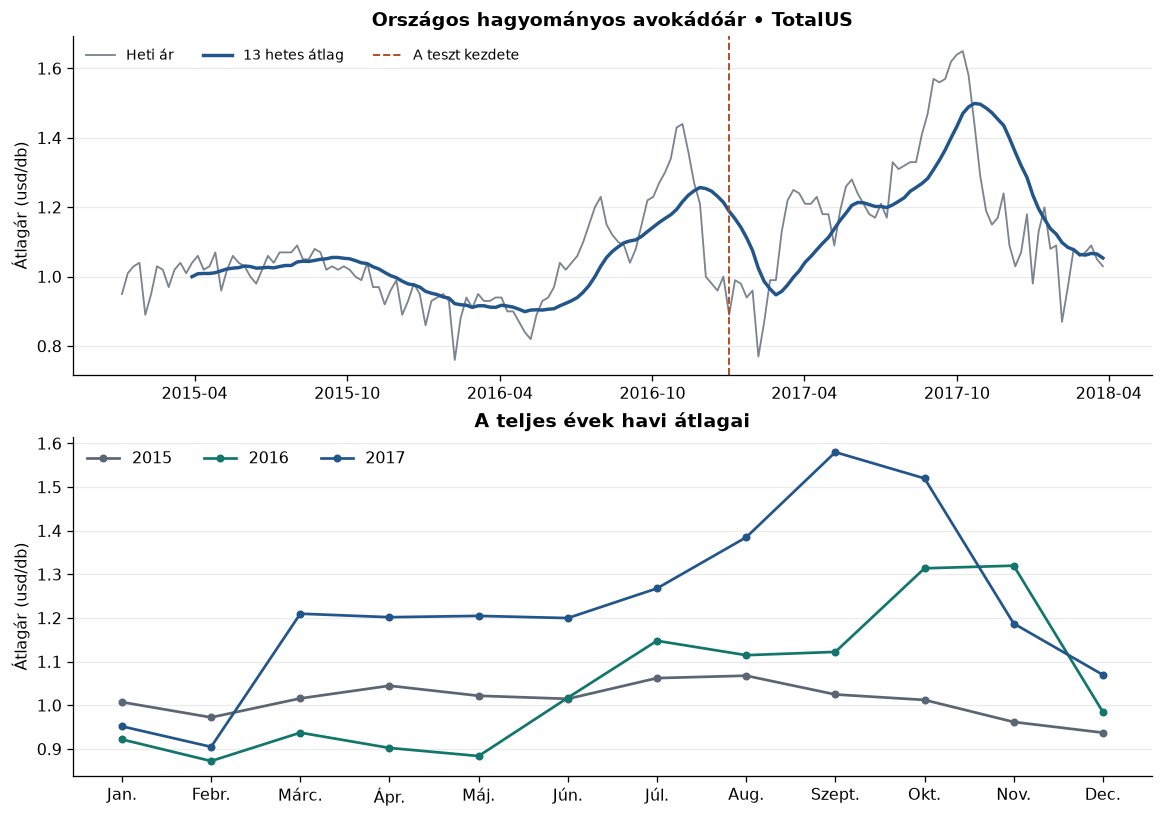

,Hetek,Átlag (usd),Minimum (usd),Maximum (usd)
Év,,,,
2015,52,1.012,0.89,1.09
2016,52,1.047,0.76,1.44
2017,53,1.222,0.77,1.65
2018,12,1.060,0.87,1.20


In [5]:
cutoff = pd.Timestamp("2017-01-01")
national = (
    data.loc[data["region"].eq("TotalUS") & data["type"].eq("conventional")]
    .set_index("Date")["AveragePrice"]
    .sort_index()
)
monthly_national = national.groupby([national.index.month, national.index.year]).mean().unstack()

fig, axes = plt.subplots(2, 1, figsize=(10, 7), layout="constrained")
axes[0].plot(national, color=GRAY, lw=1.15, alpha=0.80, label="Heti ár")
axes[0].plot(national.rolling(13).mean(), color=BLUE, lw=2.15, label="13 hetes átlag")
axes[0].axvline(cutoff, color=ORANGE, ls="--", lw=1.2, label="A teszt kezdete")
axes[0].set(title="Országos hagyományos avokádóár • TotalUS", ylabel="Átlagár (usd/db)")
axes[0].xaxis.set_major_locator(mdates.MonthLocator(interval=6))
axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
axes[0].legend(loc="upper left", ncol=3, fontsize=9)

for year, color in zip([2015, 2016, 2017], [GRAY, TEAL, BLUE]):
    axes[1].plot(monthly_national.index, monthly_national[year], marker="o",
                 ms=4, lw=1.7, label=str(year), color=color)
axes[1].set(title="A teljes évek havi átlagai", ylabel="Átlagár (usd/db)")
axes[1].set_xticks(range(1, 13), MONTH_NAMES)
axes[1].legend(loc="upper left", ncol=3)
for ax in axes:
    ax.grid(axis="y")
plt.show()

annual_price = national.groupby(national.index.year).agg(["size", "mean", "min", "max"])
display(annual_price.set_axis(["Hetek", "Átlag (usd)", "Minimum (usd)", "Maximum (usd)"], axis=1)
        .rename_axis("Év").round(3))

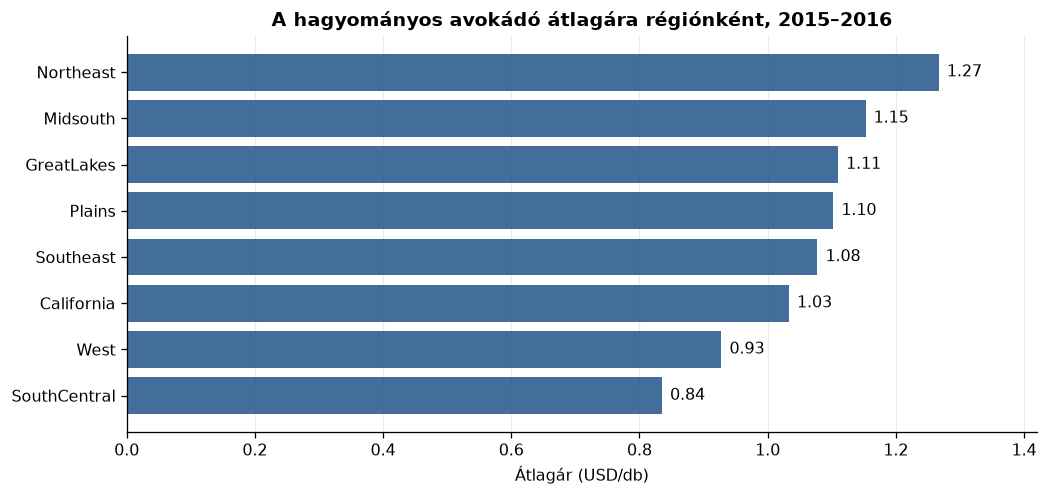

In [6]:
weekly = regional.loc[regional["type"].eq("conventional")].sort_values(["region", "Date"]).copy()
early = weekly.loc[weekly["Date"].lt(cutoff)]
early_prices = early.groupby("region")["AveragePrice"].mean().sort_values()
fig, ax = plt.subplots(figsize=(9, 4.2), layout="constrained")
bars = ax.barh(early_prices.index, early_prices, color=BLUE, alpha=0.85)
ax.bar_label(bars, fmt="%.2f", padding=5)
ax.set(title="A hagyományos avokádó átlagára régiónként, 2015–2016",
       xlabel="Átlagár (USD/db)", xlim=(0, 1.42))
ax.grid(axis="x")
plt.show()

2015 és 2017 között az éves átlag 1,01 usd-ről 1,22 usd-re növekedett. A heti ár közben többször hirtelen emelkedett, majd csökkent. 2017 azeptemberében elérte a 165 usd-t, aztán visszaesett az emelkedés előtti árfolyam alá. Az éves átlag mutat egy drégulást vagy van egy trend, de a heti árak hirtelen ugráltak fel-le.

Az őszi drágulás  2016-ban és 2017-ben is látszik. 2016-ban a legdrágább hónap  november, 2017-ben pedig szeptember volt. 2015-ben viszont nincsenek ekkora árváltozások, sokkal kiegyensúlyozottabb volt az év. Tehát az ősz több évben is drágább volt de a drágulás ideje és mértéke változott.

A régiós ábrán `SouthCentral` átlagára körülbelül 0,84 dollár, `Northeast` átlaga 1,27 dollár. Mivel nagy külömbségek vannak az átlagárakban ezért a közös alapár egy alacsonyabb átlagárú régiónál könnyen magasabb árat becsülne, egy magas átlagárúnál pedig alacsony árat becsülne. Ezért minden régió saját alapárszintet kap.




### Heti előrejelzések és időrendi teszt

- A modellek **2015–2016** adataiból tanulnak.
- A teszt **2017. január 1-től 2018. március 25-ig** tart.
- Mindig **egyetlen héttel** nézünk előre. (Például január második hetének becsléséhez január első hetének már ismert árát felhasználhatjuk.)
- A két tanított modellt a teszt alatt **nem tanítjuk újra**.
- Minden heti becsléshez csak olyan árakat használunk, amelyeket az adott hét előtt **már ismerhettünk**.

| Módszer | A becslés alapja |
|---|---|
| `Naiv` | Megismétli az adott régió előző heti árát. (Pl: ha az avokádó múlt héten 1,20 dollár volt, most is 1,20 dollárt becsül.) |
| `Trend + hónap + régió` | Figyelembe veszi, hogy hosszabb távon merre változik az ár, szeptemberben például mennyivel szokott drágább lenni, és milyen árszint jellemző az adott régióra. |
| `Trend + hónap + régió + előző hét` | Az előző modell mellé megkapja a régió legfrissebb ismert árát is. |

A két tanított modell lineáris regressziót használ. Az alapárhoz hozzáadja vagy abból levonja az idő, a hónap és a régió alapján becsült összeget. A harmadik modellbe az előző heti ár is beleszámít.

In [7]:
NAIVE = "Naiv"
CALENDAR = "Trend + hónap + régió"
WITH_LAG = "Trend + hónap + régió + előző hét"

weekly["week"] = (weekly["Date"] - weekly["Date"].min()).dt.days // 7
weekly["month"] = weekly["Date"].dt.month
weekly[NAIVE] = weekly.groupby("region")["AveragePrice"].shift(1)

month_flags = pd.get_dummies(weekly["month"], prefix="month", drop_first=True, dtype=int)
region_flags = pd.get_dummies(weekly["region"], prefix="region", drop_first=True, dtype=int)
features = pd.concat([weekly[["week", NAIVE]], month_flags, region_flags], axis=1)

calendar_columns = ["week", *month_flags.columns, *region_flags.columns]
specifications = {
    CALENDAR: calendar_columns,
    WITH_LAG: [*calendar_columns, NAIVE],
}
train_mask = weekly["Date"].lt(cutoff) & weekly[NAIVE].notna()
test_mask = weekly["Date"].ge(cutoff)
for name, columns in specifications.items():
    regression = LinearRegression()
    regression.fit(features.loc[train_mask, columns], weekly.loc[train_mask, "AveragePrice"])
    weekly.loc[test_mask, name] = regression.predict(features.loc[test_mask, columns])

model_names = [NAIVE, *specifications]
test = weekly.loc[test_mask].copy()
assert test[model_names].notna().all().all()
print(f"Tanító sorok: {train_mask.sum()} | tesztsorok: {len(test)}")
print(f"Közös tesztidőszak: {test['Date'].min():%Y-%m-%d} – {test['Date'].max():%Y-%m-%d}")
print(f"Teszthetek: {test['Date'].nunique()} | régiók: {test['region'].nunique()}")

Tanító sorok: 824 | tesztsorok: 520
Közös tesztidőszak: 2017-01-01 – 2018-03-25
Teszthetek: 65 | régiók: 8



Mindhárom módszert ugyanazon az **520 teszteseten** mérjük össze (ez 65 hét, nyolc régió). Mindkét regresszió ugyanazt a **824 tanítósort** kapja. Régiónként az első hét kimarad a tanításból, mert ahhoz még nincs korábbi ár.

- **MAE:** azt mutatja meg, átlagosan mennyivel tévedtünk.

- **RMSE:** szintén az eltérést méri, de nagyobb súlyt ad a kiugróan rossz becsléseknek. Kiszámításához négyzetre emeljük a hibákat, átlagot számolunk, majd gyököt vonunk (a végeredmény itt is dollárban értendő).

- **Átlagos előjeles hiba:** megmutatja, merre tévedünk (A becsült árból kivonjuk a tényleges árat, majd átlagolunk. A negatív eredmény azt jelzi, hogy átlagosan túl alacsony árat becsültünk).

,MAE (USD/db),RMSE (USD/db),Átlagos előjeles hiba (USD/db)
Módszer,,,
Naiv,0.0847,0.1143,-0.0005
Trend + hónap + régió + előző hét,0.0894,0.1148,-0.0334
Trend + hónap + régió,0.1604,0.2123,-0.1119


,Naiv,Trend + hónap + régió,Trend + hónap + régió + előző hét
Régió • MAE (USD/db),,,
SouthCentral,0.0605,0.1002,0.0602
Northeast,0.0657,0.1665,0.0751
West,0.0703,0.1325,0.0741
Midsouth,0.0789,0.1249,0.0805
Plains,0.0903,0.1637,0.0963
Southeast,0.0998,0.2022,0.1100
California,0.1015,0.1971,0.1049
GreatLakes,0.1103,0.1957,0.1137


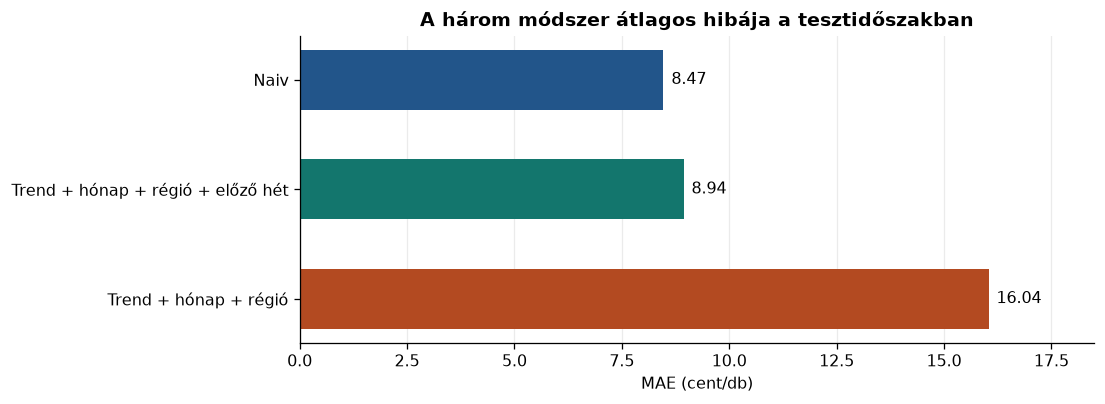

In [8]:
errors = test[model_names].sub(test["AveragePrice"], axis=0)
absolute_errors = errors.abs()
scores = pd.DataFrame({
    "MAE (USD/db)": absolute_errors.mean(),
    "RMSE (USD/db)": np.sqrt(errors.pow(2).mean()),
    "Átlagos előjeles hiba (USD/db)": errors.mean(),
}).sort_values("MAE (USD/db)")
display(scores.rename_axis("Módszer").round(4))

region_mae = absolute_errors.groupby(test["region"]).mean()
display(region_mae.sort_values(NAIVE).rename_axis("Régió • MAE (USD/db)").round(4))

model_colors = {NAIVE: BLUE, CALENDAR: ORANGE, WITH_LAG: TEAL}
fig, ax = plt.subplots(figsize=(9.5, 3.4), layout="constrained")
bars = ax.barh(scores.index, scores["MAE (USD/db)"] * 100,
               color=[model_colors[name] for name in scores.index], height=0.55)
ax.bar_label(bars, fmt="%.2f", padding=5)
ax.set(title="A három módszer átlagos hibája a tesztidőszakban",
       xlabel="MAE (cent/db)", xlim=(0, 18.5))
ax.invert_yaxis()
ax.grid(axis="x")
plt.show()


**Naiv:** Ez volt a legpontosabb, az előrejelzései átlagosan 8.47 centtel tértek el a valódi áraktól.

**Trend + Hónap + Régió:** átlagosan 16,04 centtel tévedet, mivel a korábbi évek árait követi és 2017-ben az árak jóval magasabbra kúsztak fel, ezért tévedett ekkorát.

**Trend + Hónap + Régió + Előző hét:** átlagosan 8,94 centtel tévedt, ez azt jelenti, hogy majdnem 45%-ot javítottuk az előrejelzést az előzőhét árainak hozzáadásával.

> Az eredmények arra utalnak, hogy amikor változó mértékben növekednek vagy csökkennek az árak, az előző heti árak megadásável 45% kal pontosítható az előrejelzés. Viszont még így is a nyolc régióból, hétben a naiv módszer volt pontosabb.

A pontosság régiónként is változott. A naiv becslés a `SouthCentral` régióban átlagosan 6 centet, a `GreatLakes` régióban 11 centet tévedett. Ugyanattól a módszertől tehát egyik helyen pontosabb becslést kaptunk, mint a másikon.